# EE 513 · Assignment 4 — Color Accuracy of My Camera

**Name:** Andrei Perez **Camera:** iPhone 17 Pro Max, 6.765 mm f/1.78, raw DNG

**Illuminant Rounds:** round 1 = room light, round 2 = incandescent bulb, round 3 = LED bulb.

# Setup

In [1]:
import json, struct
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cv2
import rawpy
import colour

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ROOT    = Path.cwd()                         
IMG_DIR = ROOT / "color_chart_imgs"
A1_DIR  = ROOT.parent / "A1"
OUT_DIR = ROOT / "outputs"; OUT_DIR.mkdir(exist_ok=True)

ROUNDS, CHARTS = (1, 2, 3), (1, 2, 3)
chart_file = lambda r, c: IMG_DIR / f"ILU{r}_{c}.dng"
white_file = lambda r: IMG_DIR / f"ILU{r}_W.dng"
all_files = [chart_file(r, c) for r in ROUNDS for c in CHARTS] + [white_file(r) for r in ROUNDS]
print(f"{len(all_files)} files expected, {sum(f.exists() for f in all_files)} found | colour-science {colour.__version__}")

12 files expected, 12 found | colour-science 0.4.7


## Helpers

Reused from last assignment

In [2]:
_TYPES = {1: ("B", 1), 2: ("s", 1), 3: ("H", 2), 4: ("I", 4), 5: ("II", 8), 7: ("B", 1),
          8: ("h", 2), 9: ("i", 4), 10: ("ii", 8), 11: ("f", 4), 12: ("d", 8)}
_TAGS = {0x010F: "make", 0x0110: "model", 0x829A: "exposure_s", 0x829D: "N",
         0x8827: "iso", 0x920A: "f_mm", 0xA434: "lens_model"}

def _read_ifd(fh, offset, endian):
    fh.seek(offset)
    (count,) = struct.unpack(endian + "H", fh.read(2))
    entries = [struct.unpack(endian + "HHII", fh.read(12)) for _ in range(count)]
    out = {}
    for tag, typ, n, value_or_offset in entries:
        if typ not in _TYPES:
            continue
        code, size = _TYPES[typ]
        nbytes = size * n
        if nbytes <= 4:
            raw = struct.pack(endian + "I", value_or_offset)[:nbytes]
        else:
            here = fh.tell(); fh.seek(value_or_offset); raw = fh.read(nbytes); fh.seek(here)
        if typ == 2:
            val = raw.split(b"\x00", 1)[0].decode(errors="replace").strip()
        elif typ in (5, 10):
            nums = struct.unpack(endian + code[0] * (2 * n), raw)
            vals = [a / b if b else float("nan") for a, b in zip(nums[0::2], nums[1::2])]
            val = vals[0] if n == 1 else tuple(vals)
        else:
            vals = struct.unpack(endian + code * n, raw)
            val = vals[0] if n == 1 else vals
        out[tag] = val
    return out

def read_exif(path):
    with open(path, "rb") as fh:
        endian = {b"II": "<", b"MM": ">"}[fh.read(2)]
        _, ifd0 = struct.unpack(endian + "HI", fh.read(6))
        tags = _read_ifd(fh, ifd0, endian)
        if 0x8769 in tags:
            tags.update(_read_ifd(fh, tags[0x8769], endian))
    e = {name: tags.get(tag) for tag, name in _TAGS.items()}
    e["file"] = Path(path).name
    return e

def lens_id(path):
    e = read_exif(path)
    return (e["make"], e["model"], e["lens_model"], round(e["f_mm"], 3), round(e["N"], 2))


def raw_info(path):
    with rawpy.imread(str(path)) as raw:
        return {"bayer": raw.raw_image_visible.copy(), "pattern": raw.raw_pattern.copy(),
                "desc": raw.color_desc.decode(), "black": np.array(raw.black_level_per_channel, float),
                "white": float(raw.white_level), "raw_type": str(raw.raw_type)}

def quarter_res(path, saturation=None):
    r = raw_info(path)
    sat = r["white"] if saturation is None else saturation
    sites = {ch: [(i, j) for i in range(2) for j in range(2) if r["desc"][r["pattern"][i, j]] == ch] for ch in "RGB"}
    def plane(i, j):
        black = r["black"][r["pattern"][i, j]]
        return (r["bayer"][i::2, j::2].astype(float) - black) / (sat - black)
    rgb = np.dstack([plane(*sites["R"][0]),
                     np.mean([plane(i, j) for i, j in sites["G"]], axis=0),
                     plane(*sites["B"][0])])
    layout = "".join(r["desc"][r["pattern"][i, j]] for i in range(2) for j in range(2))
    return rgb, {"layout": layout, "black": r["black"], "saturation": sat}

def show_rgb(rgb, ref=None):
    ref = rgb if ref is None else ref
    scale = 1 / np.percentile(ref, 99, axis=(0, 1))
    return np.clip(colour.cctf_encoding(np.clip(rgb * scale, 0, 1)), 0, 1)


def lab(xyz, white_xyz):
    white_xyz = np.asarray(white_xyz, float)
    return colour.XYZ_to_Lab(np.asarray(xyz, float) / white_xyz[1], colour.XYZ_to_xy(white_xyz))

def delta_e(xyz_meas, xyz_ref, white_idx):
    xyz_meas = np.asarray(xyz_meas, float) * (xyz_ref[white_idx, 1] / xyz_meas[white_idx, 1])
    w = xyz_ref[white_idx]
    return colour.delta_E(lab(xyz_meas, w), lab(xyz_ref, w), method="CIE 2000")

# Part 1 From raw file to patch values

## Item 1 · Inventory, same camera, and where the sensor really saturates

**Deliverable.** A list of your files with the round, chart, ISO, and exposure time of each, the lens_id assertion from the Project 1 page passing across all of them, the raw value at which your files actually saturate, and the fraction of each frame that reaches it.

In [9]:
rows = []
for f in all_files:
    e, r = read_exif(f), raw_info(f)
    rnd, kind = f.stem.split("_")
    rows.append(dict(file=f.name, round=int(rnd[-1]), chart=kind, iso=e["iso"], exp=e["exposure_s"],
                     raw_type=r["raw_type"], layout="".join(r["desc"][r["pattern"][i, j]] for i in range(2) for j in range(2)),
                     max=int(r["bayer"].max()), white=r["white"]))
print(f"{'file':12s} {'round':>5s} {'chart':>5s} {'ISO':>5s} {'exposure':>9s} {'raw type':>14s} {'CFA':>5s} {'max DN':>7s}")
for d in sorted(rows, key=lambda d: (d["round"], d["chart"])):
    print(f"{d['file']:12s} {d['round']:5d} {d['chart']:>5s} {d['iso']:5.0f} {'1/%d s' % round(1 / d['exp']):>9s} "
          f"{d['raw_type']:>14s} {d['layout']:>5s} {d['max']:7d}")

ids = {lens_id(f) for f in all_files}
assert len(ids) == 1, f"More than one camera: {ids}"
assert all(d["raw_type"] == "RawType.Flat" for d in rows), "A file is not a Bayer raw"
for rnd in ROUNDS:
    settings = {(d["iso"], d["exp"]) for d in rows if d["round"] == rnd}
    assert len(settings) == 1, f"Round {rnd} mixes ISO/exposure: {settings}"
print(f"\nAll {len(all_files)} files are Bayer raw from camera: {ids.pop()}")
print("ISO and exposure identical within every round (and across rounds)")

file         round chart   ISO  exposure       raw type   CFA  max DN
ILU1_1.dng       1     1   400   1/400 s   RawType.Flat  BGGR    1526
ILU1_2.dng       1     2   400   1/400 s   RawType.Flat  BGGR    1430
ILU1_3.dng       1     3   400   1/400 s   RawType.Flat  BGGR    1641
ILU1_W.dng       1     W   400   1/400 s   RawType.Flat  BGGR    2185
ILU2_1.dng       2     1   400   1/400 s   RawType.Flat  BGGR     882
ILU2_2.dng       2     2   400   1/400 s   RawType.Flat  BGGR     848
ILU2_3.dng       2     3   400   1/400 s   RawType.Flat  BGGR     863
ILU2_W.dng       2     W   400   1/400 s   RawType.Flat  BGGR     958
ILU3_1.dng       3     1   400   1/400 s   RawType.Flat  BGGR     727
ILU3_2.dng       3     2   400   1/400 s   RawType.Flat  BGGR     737
ILU3_3.dng       3     3   400   1/400 s   RawType.Flat  BGGR     739
ILU3_W.dng       3     W   400   1/400 s   RawType.Flat  BGGR     787

All 12 files are Bayer raw from camera: ('Apple', 'iPhone 17 Pro Max', 'iPhone 17 Pro Max

file          max DN  pixels ≥ 4095   fraction
ILU1_1.dng      1526              0   0.00e+00
ILU1_2.dng      1430              0   0.00e+00
ILU1_3.dng      1641              0   0.00e+00
ILU2_1.dng       882              0   0.00e+00
ILU2_2.dng       848              0   0.00e+00
ILU2_3.dng       863              0   0.00e+00
ILU3_1.dng       727              0   0.00e+00
ILU3_2.dng       737              0   0.00e+00
ILU3_3.dng       739              0   0.00e+00
ILU1_W.dng      2185              0   0.00e+00
ILU2_W.dng       958              0   0.00e+00
ILU3_W.dng       787              0   0.00e+00

Evidence from APC_0001.dng (same camera, Exercise 1): max 4095 DN, pixels piled up at 4095 DN compared to at any other top value


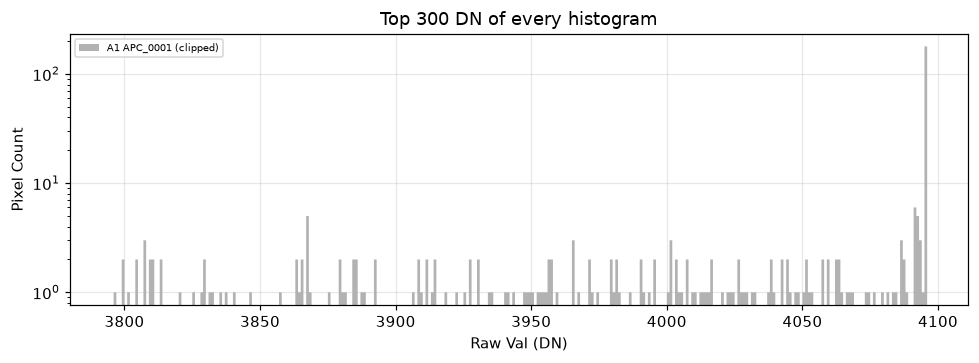


Saturation value used was 4095.0 DN and will be used for further reference


In [13]:
WHITE = rows[0]["white"]
fig, ax = plt.subplots(figsize=(9, 3.4))
for f in all_files:
    b = raw_info(f)["bayer"]
    top = b[b > WHITE - 300]
    ax.hist(top, bins=np.arange(WHITE - 300, WHITE + 2), histtype="step", label=f.stem) if top.size else None
print(f"{'file':12s} {'max DN':>7s} {'pixels ≥ 4095':>14s} {'fraction':>10s}")
for f in all_files:
    b = raw_info(f)["bayer"]
    print(f"{f.name:12s} {b.max():7d} {(b >= WHITE).sum():14d} {(b >= WHITE).mean():10.2e}")

# Compared to an actual clip image from the beginning of the course
evidence = sorted(A1_DIR.glob("APC_0001.dng"))
if evidence:
    b = raw_info(evidence[0])["bayer"]
    v, c = np.unique(b[b > WHITE - 300], return_counts=True)
    print(f"\nEvidence from {evidence[0].name} (same camera, Exercise 1): max {b.max()} DN, "
          f"pixels piled up at {b.max()} DN compared to at any other top value")
    ax.hist(b[b > WHITE - 300], bins=np.arange(WHITE - 300, WHITE + 2), histtype="stepfilled", alpha=0.3, color="k",
            label=f"A1 {evidence[0].stem} (clipped)")
ax.set(xlabel="Raw Val (DN)", ylabel="Pixel Count", yscale="log", title="Top 300 DN of every histogram")
ax.legend(fontsize=6.5, ncol=4); fig.tight_layout(); plt.show()

SATURATION = WHITE 
print(f"\nSaturation value used was {SATURATION:} DN and will be used for further reference")

> **Answer**
> All the files are Bayer raw from the same camera and the lens_id assertion passes ((Apple iPhone 17 Pro Max, back camera 6.765 mm f/1.78)) so settings are
> identical across rounds. Each round has the color charts plus a white sheet.
>
> 
> **Saturation from an image with the same phone was 4095 DN, and no frame in this report reaches it.** No patch has to be excluded for clipping.
>
> Round 2 and 3 are dim. Their brightest pixels sit only about 430 and 260 DN above black.

## Item 2 Linear colour without demosaicing

**Deliverable.** The quarter resolution image displayed, and a statement of the CFA pattern, the black level, and the saturation value you used.

ILU1_1.dng: CFA tile in a raster order BGGR to BGGR; black level [528.0, 528.0, 528.0, 528.0] DN; saturation 4095 DN
Quarter-res image 2016 × 1512 × 3, linear, range -0.0090 … 0.2703


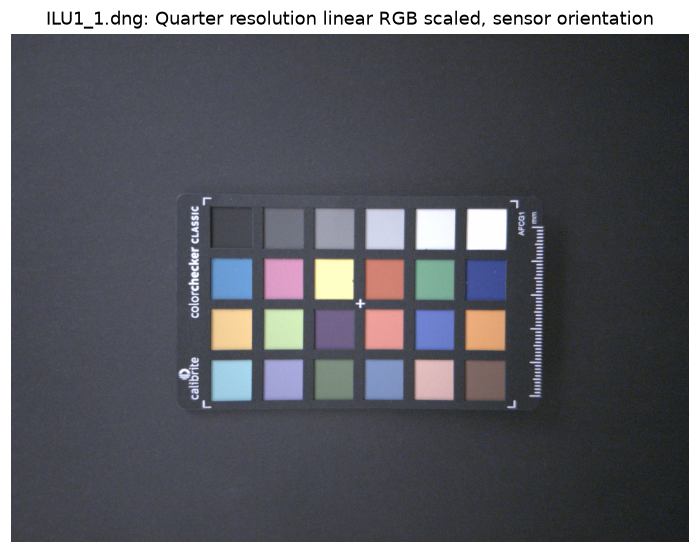

In [17]:
CAPTURE = chart_file(1, 1)
q, qinfo = quarter_res(CAPTURE, SATURATION)
print(f"{CAPTURE.name}: CFA tile in a raster order {qinfo['layout']} to BGGR; black level {qinfo['black'].tolist()} DN; "
      f"saturation {qinfo['saturation']:.0f} DN")
print(f"Quarter-res image {q.shape[1]} × {q.shape[0]} × 3, linear, range {q.min():.4f} … {q.max():.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(show_rgb(q)); ax.set_title(f"{CAPTURE.name}: Quarter resolution linear RGB scaled, sensor orientation"); ax.axis("off"); plt.show()

> **Answer**
>
> Quarter resolution image of `ILU1_1.dng` (2016 × 1512 × 3). Each 2 × 2 tile becomes (R, mean of the two G, B) with no interpolation.
> **CFA pattern BGGR** read from the file B at (0,0), G at (0,1) and (1,0), R at (1,1).
> **Black level: 528 DN** for all four sites.
>  **Saturation: 4095 DN**.
> According to theory then values are $(\text{DN} - 528)/(4095 - 528)$.

## Item 3 Lens shading

Correct that capture for lens shading using the white sheet from the same round.

**Deliverable.** The capture before and after correction; the ratio of a region at the corner of the frame to the same region at its center, measured on the white sheet itself, before and after; the profiles from all your rounds on one axis; and one sentence on what the comparison tells you.

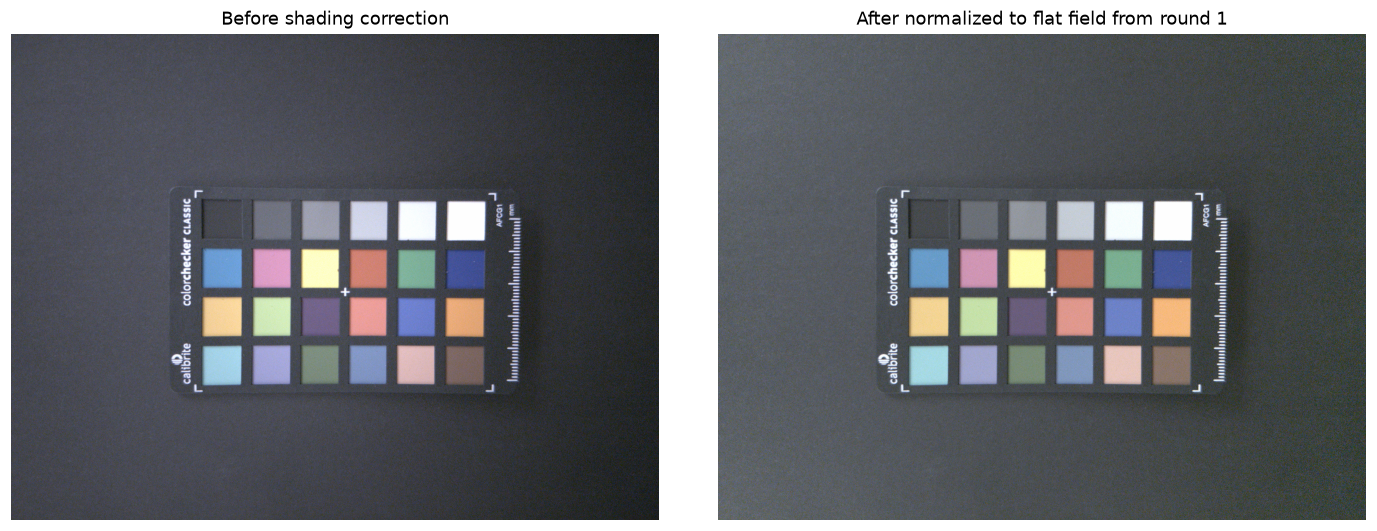

Corner / centre ratio on the white sheet itself per channel shown on RGB order
  round 1: before [0.481, 0.467, 0.48]   after [1.0, 1.0, 1.0]
  round 2: before [0.366, 0.364, 0.372]   after [1.0, 1.0, 1.0]
  round 3: before [0.316, 0.327, 0.334]   after [1.0, 1.0, 1.001]


In [20]:
# Functions center box and corner box generated with help of AI and reviewed through prints outside of this notebook
def center_box(img, frac=0.05):
    h, w = img.shape[:2]; dh, dw = int(h * frac), int(w * frac)
    return img[h // 2 - dh: h // 2 + dh, w // 2 - dw: w // 2 + dw]

def corner_box(img, frac=0.05, inset=0.03):
    h, w = img.shape[:2]; dh, dw, ih, iw = int(h * frac), int(w * frac), int(h * inset), int(w * inset)
    return img[ih: ih + 2 * dh, iw: iw + 2 * dw]                     

def flat_field(rnd, sigma=8):
    w, _ = quarter_res(white_file(rnd), SATURATION)
    smooth = np.dstack([cv2.GaussianBlur(w[..., k], (0, 0), sigma) for k in range(3)])
    return smooth / center_box(smooth).mean(axis=(0, 1))             

FLATS = {r: flat_field(r) for r in ROUNDS}
corrected = q / FLATS[1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].imshow(show_rgb(q)); axes[0].set_title("Before shading correction")
axes[1].imshow(show_rgb(corrected, ref=q / FLATS[1])); axes[1].set_title("After normalized to flat field from round 1")
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig(OUT_DIR / "item03_before_after.png", bbox_inches="tight"); plt.show()

print("Corner / centre ratio on the white sheet itself per channel shown on RGB order")
for r in ROUNDS:
    w, _ = quarter_res(white_file(r), SATURATION)
    before = corner_box(w).mean((0, 1)) / center_box(w).mean((0, 1))
    wc = w / FLATS[r]
    after = corner_box(wc).mean((0, 1)) / center_box(wc).mean((0, 1))
    print(f"  round {r}: before {np.round(before, 3).tolist()}   after {np.round(after, 3).tolist()}")

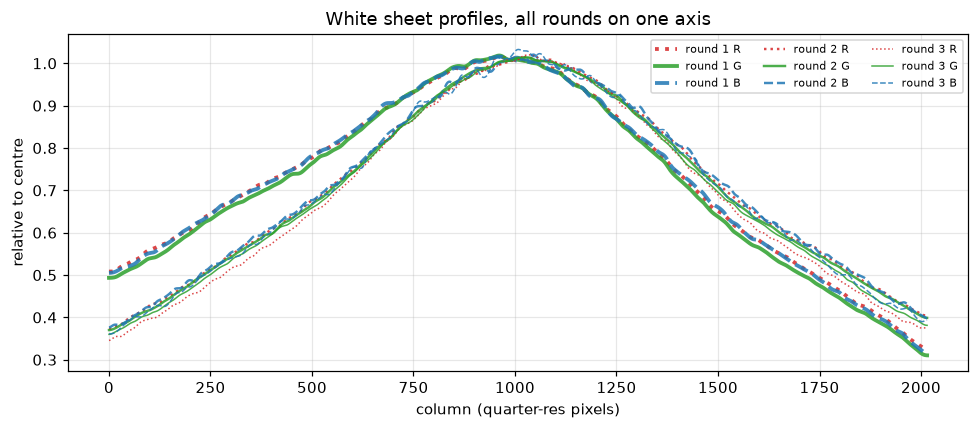

Max difference between rounds' using green profiles is 0.086 relative units


In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
styles = {0: ("tab:red", ":"), 1: ("tab:green", "-"), 2: ("tab:blue", "--")}
for r, lw in zip(ROUNDS, (2.5, 1.6, 1.0)):
    F = FLATS[r]; h = F.shape[0]
    band = F[h // 2 - 10: h // 2 + 10].mean(axis=0)
    #print(band)
    for k, name in enumerate("RGB"):
        c, ls = styles[k]
        ax.plot(band[:, k], ls, color=c, lw=lw, alpha=0.85, label=f"round {r} {name}")
ax.set(xlabel="column (quarter-res pixels)", ylabel="relative to centre", title="White sheet profiles, all rounds on one axis")
ax.legend(fontsize=7, ncol=3); fig.tight_layout(); fig.savefig(OUT_DIR / "item03_profiles.png", bbox_inches="tight"); plt.show()

prof = np.array([FLATS[r][FLATS[r].shape[0] // 2 - 10: FLATS[r].shape[0] // 2 + 10].mean(0)[:, 1] for r in ROUNDS])
print(f"Max difference between rounds' using green profiles is {np.abs(prof - prof.mean(0)).max():.3f} relative units")

> **Answer*
>
> **Corner / centre on the white sheet (R, G, B), before -> after:**
> - Round 1: 0.48 / 0.47 / 0.48 -> 1.00
> - Round 2: 0.37 / 0.36 / 0.37 -> 1.00
> - Round 3: 0.32 / 0.33 / 0.33 -> 1.00
>
> Edges get only a third to a half of the centre's light. Surprising to me, the correction is nearly the same in all three channels, but it is applied per channel anyway.
>
> The profile plot shows us that rounds 2 and 3 lie on top of each other, but round 1 has a different shape above. Falloff then is not fixed to the frame. A large part belongs to the illumination pattern, not just the lens. So a flat field from round 2 could stand in for round 3 or the other way around, but neither could stand in for round 1.

## Item 4 Locate the twenty four patches and extract their mean linear RGB. 

**Deliverable.** A figure showing the regions you sampled drawn on the chart, and your 24 by 3 table of patch means.

Side note: Noticed from experiments that sensor orientation matters so adding this to my functions.


In [25]:
REF = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"] #Hope this is the right one
NAMES = list(REF.data.keys())
XYZ_REF = colour.xyY_to_XYZ(np.array(list(REF.data.values())))    
WHITE_IDX, GRAY_IDX = 18, 21                                        

def detect_patches(img):
    # Patch centers and patch pitch
    Y = cv2.GaussianBlur(img.mean(2), (0, 0), 3)
    mask = (Y > np.percentile(Y, 20) * 1.8 + 0.002).astype(np.uint8)
    n, _, st, cen = cv2.connectedComponentsWithStats(mask)
    keep = [(cen[k], st[k, 4]) for k in range(1, n)
            if 1500 < st[k, 4] < 40000 and 0.7 < st[k, 2] / st[k, 3] < 1.4 and st[k, 4] / (st[k, 2] * st[k, 3]) > 0.75]
    a_med = np.median([a for _, a in keep])
    pts = np.array([c for c, a in keep if 0.5 * a_med < a < 1.6 * a_med])
    d = pts[:, None] - pts[None]; dist = np.hypot(d[..., 0], d[..., 1]); np.fill_diagonal(dist, np.inf)
    nn = d[np.arange(len(pts)), dist.argmin(1)]
    ang = np.median(np.arctan2(nn[:, 1], nn[:, 0]) % (np.pi / 2)); ang = ang if ang < np.pi / 4 else ang - np.pi / 2
    rot = np.array([[np.cos(ang), np.sin(ang)], [-np.sin(ang), np.cos(ang)]])
    qpts = (pts - pts.mean(0)) @ rot.T
    step = np.median(dist.min(1))
    col = np.round((qpts[:, 0] - qpts[:, 0].min()) / step).astype(int)
    row = np.round((qpts[:, 1] - qpts[:, 1].min()) / step).astype(int)
    assert col.max() == 5 and row.max() == 3, f"grid not 6 × 4 (cols ≤ {col.max()}, rows ≤ {row.max()})"
    H, _ = cv2.findHomography(np.c_[col, row].astype(np.float32), pts.astype(np.float32), cv2.RANSAC, 5.0)
    gc, gr = np.meshgrid(np.arange(6), np.arange(4))
    centres = cv2.perspectiveTransform(np.c_[gc.ravel(), gr.ravel()].astype(np.float32)[None], H)[0]
    return centres.reshape(4, 6, 2), np.sqrt(a_med), len(pts)

def patch_means(img, centres, size):
    half = int(size / 4)                                          
    out = np.zeros((4, 6, 3)); boxes = np.zeros((4, 6, 4), int)
    for r in range(4):
        for c in range(6):
            x, y = np.round(centres[r, c]).astype(int)
            out[r, c] = img[y - half: y + half, x - half: x + half].mean(axis=(0, 1))
            boxes[r, c] = (x - half, y - half, 2 * half, 2 * half)
    return out, boxes

def to_reference_order(grid_vals, grid_boxes):
    best = None
    for k in (0, 2):
        v = np.rot90(grid_vals, k).reshape(24, 3); b = np.rot90(grid_boxes, k).reshape(24, 4)
        score = np.corrcoef(np.log(v.mean(1) + 1e-6), np.log(XYZ_REF[:, 1]))[0, 1]
        if best is None or score > best[0]:
            best = (score, k, v, b)
    return best

def measure_chart(path, rnd):
    img = quarter_res(path, SATURATION)[0] / FLATS[rnd]
    centres, size, n_found = detect_patches(img)
    vals, boxes = patch_means(img, centres, size)
    score, k, rgb, boxes = to_reference_order(vals, boxes)
    neutral_ok = np.all(np.diff(rgb[18:24].mean(1)) < 0)
    return dict(img=img, rgb=rgb, boxes=boxes, rot=90 * k, score=score, found=n_found, neutral_ok=neutral_ok)

M11 = measure_chart(CAPTURE, 1)
c_meas = M11["rgb"]
print(f"{CAPTURE.name} =  {M11['found']} patches segmented, grid rotated {M11['rot']} degrees to reference order "
      f"luminance rank correlation {M11['score']:.3f}; neutrals decreasing 19 to 24: {M11['neutral_ok']}")
print(f"Patch 1 = {NAMES[0]}, patch 19 = {NAMES[18]}\n")
print(f"{'#':>2s} {'patch':16s} {'R':>8s} {'G':>8s} {'B':>8s}")
for i, (nm, v) in enumerate(zip(NAMES, c_meas)):
    print(f"{i + 1:2d} {nm:16s} {v[0]:8.5f} {v[1]:8.5f} {v[2]:8.5f}")

ILU1_1.dng: 22 patches segmented, grid rotated 180° to reference order (luminance-rank correlation 0.985); neutrals decreasing 19→24: True
Patch 1 = dark skin, patch 19 = white 9.5 (.05 D)

 # patch                   R        G        B
 1 dark skin         0.03534  0.03839  0.00888
 2 light skin        0.11307  0.12252  0.03036
 3 blue sky          0.03103  0.06801  0.03010
 4 foliage           0.02711  0.05649  0.01122
 5 blue flower       0.05069  0.08338  0.03668
 6 bluish green      0.05412  0.15131  0.04620
 7 orange            0.13154  0.10627  0.01250
 8 purplish blue     0.02186  0.04894  0.03423
 9 moderate red      0.10462  0.06843  0.01618
10 purple            0.02014  0.02406  0.01203
11 yellow green      0.07942  0.16366  0.02385
12 orange yellow     0.12696  0.14266  0.01772
13 blue              0.00879  0.02091  0.01910
14 green             0.02794  0.09326  0.01706
15 red               0.07567  0.04253  0.00835
16 yellow            0.15562  0.21909  0.02581
17 magenta 

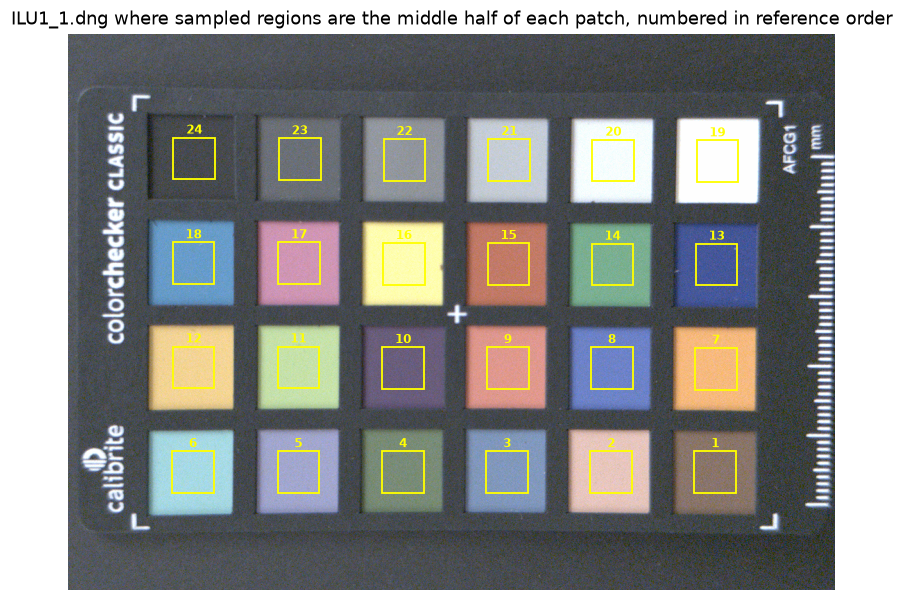

In [27]:
def plot_sampling(meas, title, save=None):
    fig, ax = plt.subplots(figsize=(9, 6.8))
    ax.imshow(show_rgb(meas["img"]))
    for i, (x, y, w, h) in enumerate(meas["boxes"]):
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="yellow", lw=1.2))
        ax.text(x + w / 2, y - 6, str(i + 1), color="yellow", ha="center", fontsize=8, weight="bold")
    xs, ys = meas["boxes"][:, 0], meas["boxes"][:, 1]
    ax.set_xlim(xs.min() - 150, xs.max() + 200); ax.set_ylim(ys.max() + 200, ys.min() - 150)
    ax.set_title(title); ax.axis("off")
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()

plot_sampling(M11, f"{CAPTURE.name} where sampled regions are the middle half of each patch, numbered in reference order")

# Part 2 · White balance and the colour matrix

## Item 5 White balance gains from a mid grey

**Deliverable.** The three gains, normalized to the green channel, and the patch means after balancing.

In [30]:
def wb_gains(rgb, idx=GRAY_IDX):
    return rgb[idx, 1] / rgb[idx]                                

gains = wb_gains(c_meas)
c_bal = c_meas * gains
print(f"RGB gains normalised to green are {np.round(gains, 4).tolist()}\n")
print(f"{'#':>2s} {'patch':16s} {'R':>8s} {'G':>8s} {'B':>8s}")
for i, (nm, v) in enumerate(zip(NAMES, c_bal)):
    print(f"{i + 1:2d} {nm:16s} {v[0]:8.5f} {v[1]:8.5f} {v[2]:8.5f}")
print("\nNeutrals after balancing (R/G, B/G) are ", [f"{v[0] / v[1]:.3f}/{v[2] / v[1]:.3f}" for v in c_bal[18:24]])

RGB gains normalised to green are [1.6398, 1.0, 3.2726]

 # patch                   R        G        B
 1 dark skin         0.05796  0.03839  0.02906
 2 light skin        0.18540  0.12252  0.09936
 3 blue sky          0.05087  0.06801  0.09852
 4 foliage           0.04445  0.05649  0.03672
 5 blue flower       0.08312  0.08338  0.12005
 6 bluish green      0.08875  0.15131  0.15120
 7 orange            0.21569  0.10627  0.04089
 8 purplish blue     0.03584  0.04894  0.11203
 9 moderate red      0.17156  0.06843  0.05294
10 purple            0.03303  0.02406  0.03937
11 yellow green      0.13023  0.16366  0.07806
12 orange yellow     0.20819  0.14266  0.05798
13 blue              0.01441  0.02091  0.06250
14 green             0.04582  0.09326  0.05584
15 red               0.12409  0.04253  0.02732
16 yellow            0.25518  0.21909  0.08446
17 magenta           0.14480  0.06579  0.08874
18 cyan              0.03209  0.07200  0.11441
19 white 9.5 (.05 D)  0.32150  0.32387  0.31052
20

## Item 6 Error before the matrix is fitted

**Deliverable.** Mean and worst ΔE across the twenty four patches, and the name of the metric.

In [31]:
SRGB_TO_XYZ = colour.RGB_COLOURSPACES["sRGB"].matrix_RGB_to_XYZ
de_before = delta_e(c_bal @ SRGB_TO_XYZ.T, XYZ_REF, WHITE_IDX)
print(f"White balance only, balanced RGB treated as linear sRGB:")
print(f"  mean ΔE = {de_before.mean():.2f}   worst ΔE  = {de_before.max():.2f} ({NAMES[de_before.argmax()]})")

White balance only, balanced RGB treated as linear sRGB:
  mean ΔE = 11.78   worst ΔE  = 19.60 (yellow green)


> **Answer**
> mean ΔE = 11.78   worst ΔE  = 19.60 (yellow green)
> Metric: CIEDE 2000 with reference patch 19 as the white point

## Item 7 · Fit the 3 × 3 matrix

**Deliverable.** The matrix, and one sentence on whether its rows sum to something close to preserving a neutral.


In [38]:
def fit_ccm(c, t):
    M_T, *_ = np.linalg.lstsq(c, t, rcond=None)               
    return M_T.T

M = fit_ccm(c_bal, XYZ_REF)
print("M matrix of a balanced camera RGB to XYZ = ")
print(M)
rs = M.sum(axis=1)
d50 = XYZ_REF[WHITE_IDX] / XYZ_REF[WHITE_IDX, 1]
print(f"\nRow sums / Y row sum    = {np.round(rs / rs[1], 4).tolist()}")
print(f"Reference white XYZ / Y  = {np.round(d50, 4).tolist()}")
print(f"Neutral 1,1,1 maps to xy {np.round(colour.XYZ_to_xy(rs), 4).tolist()} vs reference white xy "
      f"{np.round(colour.XYZ_to_xy(XYZ_REF[WHITE_IDX]), 4).tolist()}")

M matrix of a balanced camera RGB to XYZ = 
[[ 1.41619905  0.90560281  0.28558678]
 [ 0.17888033  2.58562287 -0.06295034]
 [ 0.03701698 -0.98819822  3.20860066]]

Row sums / Y row sum    = [0.9651, 1.0, 0.8356]
Reference white XYZ / Y  = [0.958, 1.0, 0.7877]
Neutral 1,1,1 maps to xy [0.3446, 0.357] vs reference white xy [0.3489, 0.3642]


> **Answer**
>
> $$\mathbf M = \begin{pmatrix} 1.416 & 0.906 & 0.286\\ 0.179 & 2.586 & -0.063\\ 0.037 & -0.988 & 3.209 \end{pmatrix}$$
>
> The rows sum to [0.965, 1, 0.836] relative to the Y row, close to the reference white's [0.958, 1, 0.788].
>
> A neutral therefore maps to xy [0.345, 0.357] against the white patch's [0.349, 0.364]. This means it is close to preserving neutrals without being constrained to, with a slight blue bias.
> In my understanding, preserving a neutral here means the row sums point along the D50 white, not that they equal 1.

## Item 8 Error after the matrix

**Deliverable.** A figure of per patch ΔE before and after, the mean and worst value for each, the names of the two or three worst patches, and your written explanation.

                         mean ΔE    worst ΔE
white balance only         11.78       19.60
plus 3×3 matrix             2.57        5.45

Worst after the matrix: purplish blue (5.45), cyan (4.86), blue (4.00)


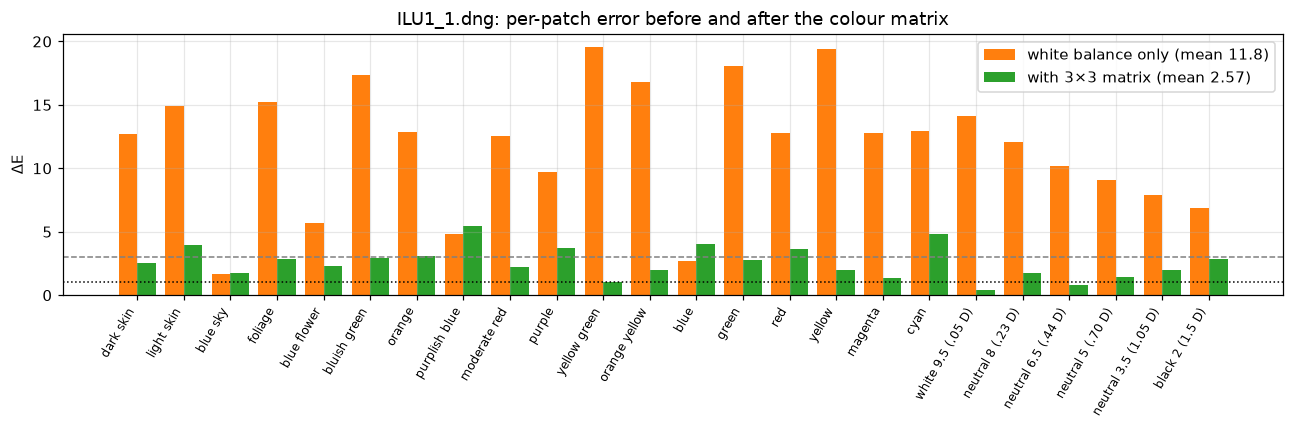

In [41]:
de_after = delta_e(c_bal @ M.T, XYZ_REF, WHITE_IDX)
print(f"{'':22s}{'mean ΔE':>10s}{'worst ΔE':>12s}")
print(f"{'white balance only':22s}{de_before.mean():10.2f}{de_before.max():12.2f}")
print(f"{'plus 3×3 matrix':22s}{de_after.mean():10.2f}{de_after.max():12.2f}")
worst3 = np.argsort(de_after)[::-1][:3]
print("\nWorst after the matrix:", ", ".join(f"{NAMES[i]} ({de_after[i]:.2f})" for i in worst3))

x = np.arange(24)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(x - 0.2, de_before, 0.4, label=f"white balance only (mean {de_before.mean():.1f})", color="tab:orange")
ax.bar(x + 0.2, de_after, 0.4, label=f"with 3×3 matrix (mean {de_after.mean():.2f})", color="tab:green")
ax.axhline(1, ls=":", c="k", lw=1); ax.axhline(3, ls="--", c="gray", lw=1)
ax.set_xticks(x, NAMES, rotation=60, ha="right", fontsize=8); ax.set_ylabel("ΔE")
ax.set_title(f"{CAPTURE.name}: per-patch error before and after the colour matrix"); ax.legend()
fig.tight_layout(); fig.savefig(OUT_DIR / "item08_delta_e.png", bbox_inches="tight"); plt.show()

> **Answer**
>
> The three worst patches after the matrix are 5.45, 4.86 and 4. 0 mwhich represent a purpish blue, cyan and blue respectively.
>
> Reasing more about this topic I have an understanding that the residual cannot reach zero because the spectral sensitivities are not a linear combination of the CIE colour matching functions. Thus, the camera sees some pairs of spectra differently from how the eye does, and no fixed 3 × 3 matrix can map both correctly. Im simple words, the error depends on each spectrum per patch and not only on its colour. Seems like the fit also minimises XYZ error, which is dominated by bright patches, rather than ΔE, so a refit cannot be expected to remove it.

# Part 3 How much of this belongs to the chart?

## Item 9 Items 5–8 for all three charts under round 1

Round 1 is used because it is by far the brightest with the highest SNR.

**Deliverable.** Three mean and three worst ΔE values, and a comment on whether the three matrices resemble one another. Compare their columns as directions rather than element by element: several elements of a color matrix sit near zero, and their relative differences explode without meaning anything.

In [49]:
def analyse(rnd, chart):
    m = measure_chart(chart_file(rnd, chart), rnd)
    g = wb_gains(m["rgb"]); cb = m["rgb"] * g
    Mx = fit_ccm(cb, XYZ_REF)
    return dict(meas=m, gains=g, bal=cb, M=Mx,
                de_before=delta_e(cb @ SRGB_TO_XYZ.T, XYZ_REF, WHITE_IDX),
                de_after=delta_e(cb @ Mx.T, XYZ_REF, WHITE_IDX))

R1 = {c: analyse(1, c) for c in CHARTS}
print(f"{'chart':>5s} {'rot':>4s} {'gains R,G,B':>24s} {'before mean/worst':>18s} {'after mean/worst':>17s}  worst patch")
for c, a in R1.items():
    print(f"{c:5d} {a['meas']['rot']:4d} {str(np.round(a['gains'], 3).tolist()):>24s} "
          f"{a['de_before'].mean():9.2f}/{a['de_before'].max():5.2f} {a['de_after'].mean():9.2f}/{a['de_after'].max():5.2f}  "
          f"{NAMES[a['de_after'].argmax()]}")

for c, a in R1.items():
    print(f"\nM, chart {c}:"); print(np.array2string(a["M"], precision=4, suppress_small=True))

def col_angles(Ma, Mb):
    ua, ub = Ma / np.linalg.norm(Ma, axis=0), Mb / np.linalg.norm(Mb, axis=0)
    return np.degrees(np.arccos(np.clip((ua * ub).sum(0), -1, 1)))
print("\nAngle between corresponding columns R,G,B in degrees:")
for a_, b_ in [(1, 2), (1, 3), (2, 3)]:
    print(f"  chart {a_} vs {b_}: {np.round(col_angles(R1[a_]['M'], R1[b_]['M']), 2).tolist()}   "
          f"column-length ratios {np.round(np.linalg.norm(R1[a_]['M'], axis=0) / np.linalg.norm(R1[b_]['M'], axis=0), 3).tolist()}")

chart  rot              gains R,G,B  before mean/worst  after mean/worst  worst patch
    1  180       [1.64, 1.0, 3.273]     11.78/19.60      2.57/ 5.45  purplish blue
    2  180      [1.647, 1.0, 3.314]     11.64/19.04      2.41/ 4.94  purplish blue
    3  180      [1.653, 1.0, 3.308]     11.80/19.89      2.36/ 5.12  purplish blue

M, chart 1:
[[ 1.4162  0.9056  0.2856]
 [ 0.1789  2.5856 -0.063 ]
 [ 0.037  -0.9882  3.2086]]

M, chart 2:
[[ 1.4995  0.8748  0.3137]
 [ 0.245   2.567  -0.0184]
 [ 0.0609 -0.9839  3.2078]]

M, chart 3:
[[ 1.4481  0.8091  0.3018]
 [ 0.2223  2.4708 -0.0338]
 [ 0.0802 -1.036   3.133 ]]

Angle between corresponding columns R,G,B in degrees:
  chart 1 vs 2: [2.23, 0.47, 0.94]   column-length ratios [0.939, 1.01, 1.0]
  chart 1 vs 3: [2.25, 2.19, 0.65]   column-length ratios [0.973, 1.041, 1.024]
  chart 2 vs 3: [1.0, 1.9, 0.3]   column-length ratios [1.036, 1.031, 1.024]


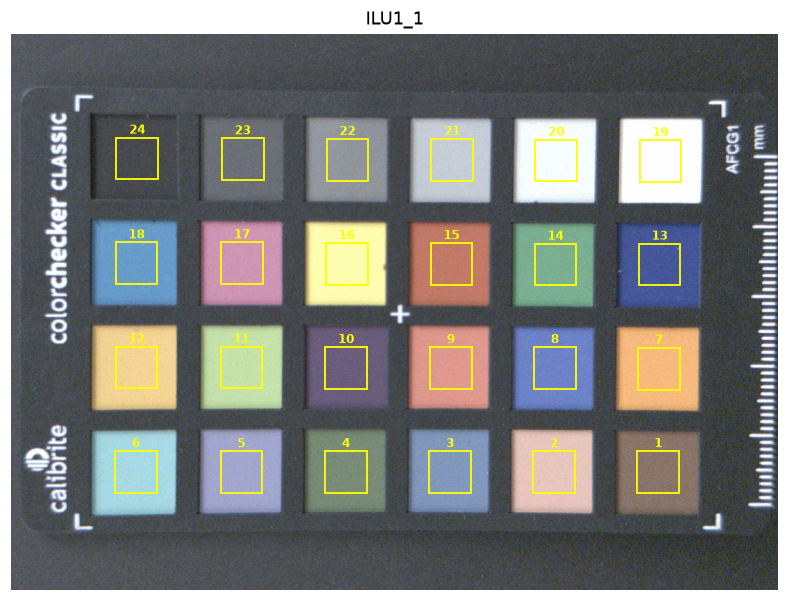

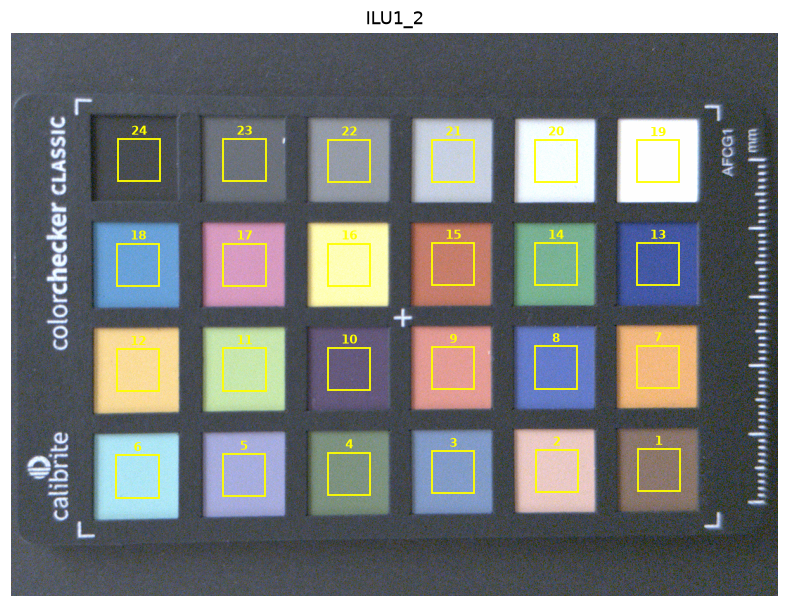

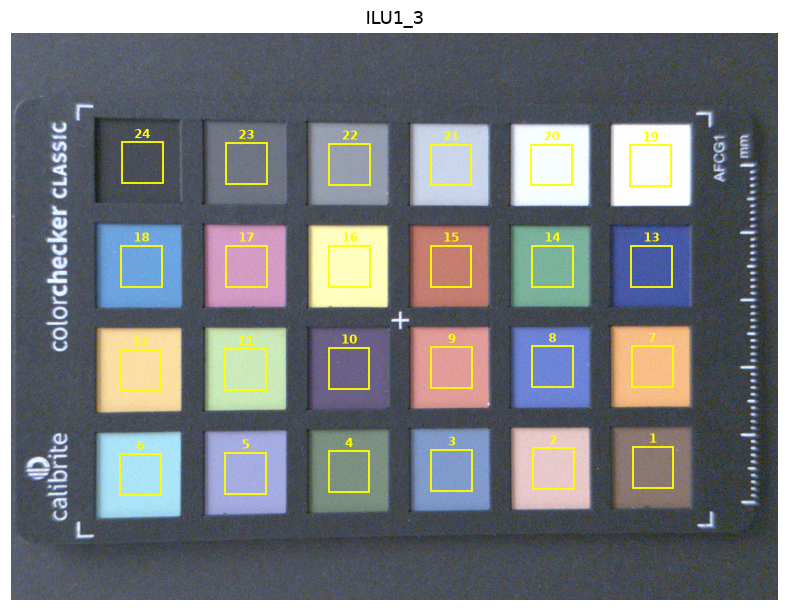

In [50]:
for c in CHARTS:
    plot_sampling(R1[c]["meas"], f"ILU1_{c}")

> **Answer**
>
> | Chart | Mean ΔE before | Mean ΔE after | Worst after |
> |---|---|---|---|
> | 1 | 11.78 | 2.57 | 5.45 (purplish blue) |
> | 2 | 11.64 | 2.41 | 4.94 (purplish blue) |
> | 3 | 11.80 | 2.36 | 5.12 (purplish blue) |
>
> The three matrices look almost identical. I evaluated this by also seeing the corresponding columns point within 0.3–2.3 degrees of each other, with lengths relatively close, and all three charts fail worst on the same patch. Element by element they can output a more different result at the small entries, which is why columns are compared as directions.

## Item 10 Project 1 color entries

**Deliverable.**  Your mean ΔE after correction as a value with an uncertainty, and the five color entries of your Project 1 results.json, which are the metric, the reference set, the mean ΔE before and after correction, and the worst patch after correction.

In [53]:
means_after = np.array([R1[c]["de_after"].mean() for c in CHARTS])
means_before = np.array([R1[c]["de_before"].mean() for c in CHARTS])
worst_patch = {c: NAMES[R1[c]["de_after"].argmax()] for c in CHARTS}
print(f"Mean ΔE after correction {np.round(means_after, 3).tolist()}")
print(f"  -> {means_after.mean():.2f} ± {means_after.std(ddof=1):.2f} ")
print(f"Mean ΔE before correction:          {means_before.mean():.2f} ± {means_before.std(ddof=1):.2f}")

de_stack = np.array([R1[c]["de_after"] for c in CHARTS])
wi = int(de_stack.mean(0).argmax())

# Used AI here to understand a good way to organize this json for future work
results_color = {
    "color_metric": "CIEDE2000",
    "color_reference": "colour-science ColorChecker24 - After November 2014 (D50), white = patch 19",
    "color_mean_delta_e_before": round(float(means_before.mean()), 2),
    "color_mean_delta_e_after": round(float(means_after.mean()), 2),
    "color_worst_patch_after": {"patch": NAMES[wi], "delta_e": round(float(de_stack.mean(0)[wi]), 2)},
}
results_color["color_mean_delta_e_after_uncertainty"] = round(float(means_after.std(ddof=1)), 2)
(OUT_DIR / "results_color.json").write_text(json.dumps(results_color, indent=2))
print(json.dumps(results_color, indent=2))

Mean ΔE after correction [2.571, 2.407, 2.357]
  -> 2.45 ± 0.11 
Mean ΔE before correction:          11.74 ± 0.09
{
  "color_metric": "CIEDE2000",
  "color_reference": "colour-science ColorChecker24 - After November 2014 (D50), white = patch 19",
  "color_mean_delta_e_before": 11.74,
  "color_mean_delta_e_after": 2.45,
  "color_worst_patch_after": {
    "patch": "purplish blue",
    "delta_e": 5.17
  },
  "color_mean_delta_e_after_uncertainty": 0.11
}


# Part 4 How much of it belongs to the illuminant?

## Item 11 & 12 Second and Third iluminant

In [55]:
transfer = {1: dict(gains=gains, de=de_after)}
refit = {1: de_after}
for rnd in (2, 3):
    m = measure_chart(chart_file(rnd, 1), rnd)
    g = wb_gains(m["rgb"]); cb = m["rgb"] * g
    transfer[rnd] = dict(meas=m, gains=g, de=delta_e(cb @ M.T, XYZ_REF, WHITE_IDX))     
    refit[rnd] = delta_e(cb @ fit_ccm(cb, XYZ_REF).T, XYZ_REF, WHITE_IDX)            # keeping this as a reference

print(f"{'round':>5s} {'WB gains R,G,B':>24s} {'transferred M: mean/worst':>27s} {'refitted M: mean/worst':>24s}")
for rnd in ROUNDS:
    t = transfer[rnd]
    print(f"{rnd:5d} {str(np.round(t['gains'], 3).tolist()):>24s} {t['de'].mean():15.2f}/{t['de'].max():5.2f}"
          f"{refit[rnd].mean():18.2f}/{refit[rnd].max():5.2f}")


print("\nWhite sheet, raw camera ratios at the centre R/G , B/G")
for rnd in ROUNDS:
    w = center_box(quarter_res(white_file(rnd), SATURATION)[0]).mean((0, 1))
    print(f"  round {rnd}: R/G {w[0] / w[1]:.3f}   B/G {w[2] / w[1]:.3f}")

round           WB gains R,G,B   transferred M: mean/worst   refitted M: mean/worst
    1       [1.64, 1.0, 3.273]            2.57/ 5.45              2.57/ 5.45
    2       [1.44, 1.0, 3.483]            2.77/ 7.43              2.72/ 8.42
    3      [1.364, 1.0, 3.501]            4.01/ 7.78              3.24/ 8.78

White sheet, raw camera ratios at the centre R/G , B/G
  round 1: R/G 0.599   B/G 0.315
  round 2: R/G 0.695   B/G 0.285
  round 3: R/G 0.760   B/G 0.282


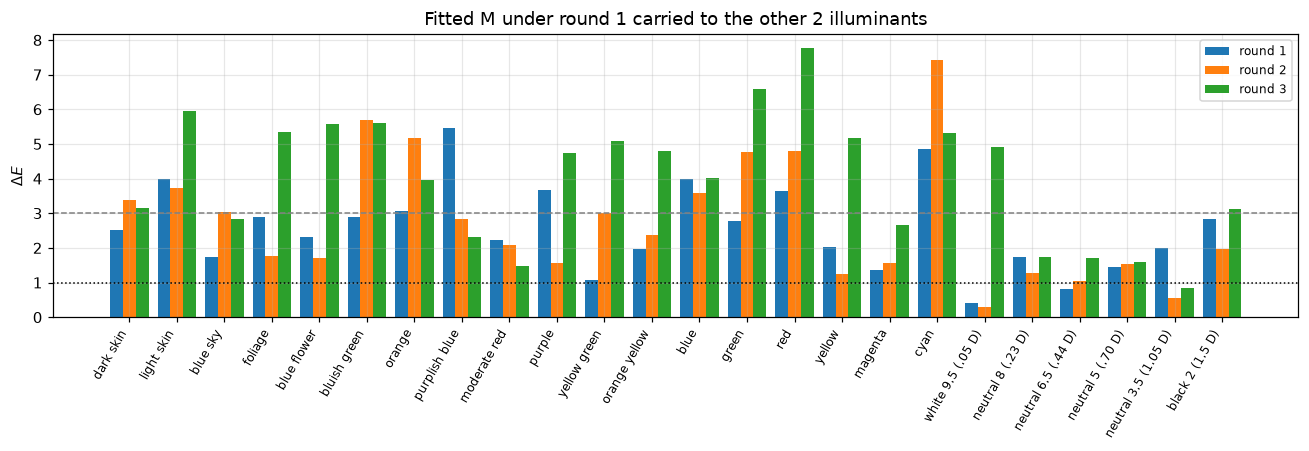

In [61]:
x = np.arange(24)
fig, ax = plt.subplots(figsize=(12, 4.2))
for k, rnd in enumerate(ROUNDS):
    ax.bar(x + (k - 1) * 0.27, transfer[rnd]["de"], 0.27,
           label=f"round {rnd}")
ax.axhline(1, ls=":", c="k", lw=1); ax.axhline(3, ls="--", c="gray", lw=1)
ax.set_xticks(x, NAMES, rotation=60, ha="right", fontsize=8); ax.set_ylabel(r"$\Delta E$")
ax.set_title("Fitted M under round 1 carried to the other 2 illuminants"); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

> **Unmder Second Iluminant**
>
>
> | Light | Mean ΔE | Worst ΔE |
> |---|---|---|
> | Round 1, room light (matrix fitted here) | 2.57 | 5.45 (purplish blue) |
> | **Round 2, incandescent (transferred)** | **2.77** | **7.43 (cyan)** |
>

> **Under Third Iluminant**
>
> | Light | Mean ΔE | Worst ΔE |
> |---|---|---|
> | Round 1, room light (fitted) | 2.57 | 5.45 |
> | Round 2, incandescent (transferred) | 2.77 | 7.43 |
> | **Round 3, LED (transferred)** | **4.01** | **7.78 (red)** |
>
> Higher cost for refitting

## Item 13 Interpretation

> Round 1 is room light, round 2 an incandescent bulb, and round 3 an LED bulb.
> The white sheets help confirm this design incandescent and LED have nearly the same colour temperature (B/G 0.285 vs 0.282), while the room light is clearly bluer.
> Transfer to the LED degraded more. We see a mean delta E which rose from 2.57 to 4.01 with a worst at red 7.78, against only 2.77 for the incandescent bulb with a cyan as the worst 7.43, even though the incandescent bulb sits just as far from the room light in colour temperature. This is interesting since now one can assume the degradation tracks the spectral shape and not the color temperature. The incandescent light spectrum transfers almost for free, because a matrix refitted under it would only reach 2.72. From material seen online I found that the LED's narrow blue peak and phosphor hump make the camera and the eye disagree differently than under smooth light, we see it here as the refitted matrix would reach 3.24. This means a 0.8 delta E is the cost of using the room-light matrix.
>
> I understand now that a single matrix stored in a camera can be close across a range of colour temperatures, but it cannot be correct under every light. DNG tends to interpolate between calibration matrices by color temperature so withouth spectrum accountability one cannot anticipate an LED's spectral shape.It is also important to highlight that the LED was also the dimmest scenario which could add some error unrelatred to the matrix.

# Part 5 · Reflections

## What did you learn?

> Several concepts were understood here and the one that I can highlight is that color accuracy is basically a fit with a floor and no amount of fitting goes further because the camera is adifferent observer from the eye.
> Another important copncept I learned was from comparing the charts under the same light since this gave me a better idea on how to turn a numbert into a mesasurment with an uncertainty, and showed that the charts are not the limiting factor.
> Futhermore, carrying the matrix across lights was the best lesson since I noticed how colour temperature mattered less than spectral shape.
>
> Lastly, I learned as well that the sensor orientation can somehow influence many of these results.

## Questions for the instructor

> 1. For the white point I used the reference patch 19 for both the measurement and the reference, after scaling the measurement's Y to match. Is that supposed to be the "use a measured neutral patch as the reference white"?
> 2. Under the LED, the neutral ladder is not perfectly neutral after one gain per channel . Is that expected?
> 3. Is the room light's spectrum actually smooth? 

AI was used in some formatting as described within cells. Functions made with the help of AI were tested visually.